# Part 13: Optimal proposals beyond the linear-Gaussian case

Part 3 rescued the `M < d` particle filter with the **locally optimal proposal**
`q(x_t | x_{t-1}, y_t) = p(x_t | x_{t-1}, y_t)` of Doucet, Godsill & Andrieu (2000). That rescue
leans on a closed form which exists *only* because the model is linear-Gaussian:

```
Sigma* = (Q^-1 + H' R^-1 H)^-1,    m*_i = Sigma* (Q^-1 F x_{t-1}^i + H' R^-1 y_t)
```

and the incremental weight then collapses to `p(y_t | x_{t-1}^i)`, which does not depend on the
newly sampled state at all. Once `f` is nonlinear neither thing is true. The conditional has no
closed form, so the proposal must be **approximated**, and the weight is the full importance ratio

```
w_t^i  proportional to  G_t(x_t^i) p(x_t^i | x_{t-1}^i) / q(x_t^i | x_{t-1}^i, y_t)
```

whose variance is no longer minimised by construction. **How much of the rescue survives the
approximation** is the question.

Part 9 sharpened the target: over 39 observation functions, the only failure mode it found twice
over is a **sharp likelihood that must be satisfied at two well-separated modes** -- which is a
proposal problem rather than a model one. It named two cells:

- `sq_only` (`f(x) = x^2`) at `b = 0.9`: the one cell where more particles stopped helping, fitted
  slope `-0.342` against the theoretical `-0.5`.
- `abs_only` (`f(x) = |x|`) at `b = 1`: non-injective, so the posterior has modes at `+-x_t` whose
  separation `2|x_t|` **grows with the state** while any local proposal moves particles `O(1)` per
  step. Part 9 measured up to a `6.5x` cost from this.

Four proposals are run, in `d = 1` where `grid_filter_obs` gives an exact benchmark:

| proposal | `q` | available in practice? |
|---|---|---|
| `bootstrap` | `p(x_t \| x_{t-1})` | yes -- the baseline of Parts 1-9 |
| `exact` | `p(x_t \| x_{t-1}, y_t)`, by numerical inversion on a local grid | **no** -- a ceiling, not a method |
| `linear` | Gaussian conditional of `f` linearised at the prior mean | yes -- the textbook EKF proposal |
| `mixture` | the same linearisation at *every* local maximum of the likelihood | yes |

`exact` is the point of the design. It is unaffordable in `d > 1` and is included so that the two
approximations can be scored against **what the rescue is actually worth**, rather than only
against the bootstrap filter. The gap between `exact` and `linear` is the cost of approximating.

Two further variants appear in Section 6, once the measurement has said why they are needed.

## Section 1: settings, and the predictions, written down first

Parts 11 and 12 established that single-dataset claims in this project fail at a rate of about one
in four, and that the two categories at risk are **extreme-value statistics free to move** and
**shape claims without an effect size**. Part 9's `-0.342` is a shape claim from one dataset, so
Section 3 tests it before anything is built on it.

The predictions below are registered now and scored in Section 10. The pilot runs behind this
notebook saw single-dataset numbers at `b = 1` swing by a factor of six between neighbouring `N`,
so nothing here is a prediction of a number already seen with error bars.

In [1]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
import observation_models as om
from filters import kalman_filter_md, particle_filter_md

QUICK = False        # smoke-test switch: fewer datasets and a shorter run

Q       = 1.0
T       = 300 if not QUICK else 80
H       = 0.002                                    # grid spacing; checked in Section 2
N1      = 1000                                     # the reference particle count
NS      = [250, 1000, 4000, 16000] if not QUICK else [250, 1000]
ND      = 20 if not QUICK else 3                   # datasets, fixed-N sections
ND_S    = 12 if not QUICK else 3                   # datasets, the N sweeps
ND_B    = 10 if not QUICK else 2                   # datasets, the breadth table
GRID_N  = 201                                      # "exact" proposal grid; Section 2
DF      = 5.0                                      # t tail weight, Section 6
CELLS   = [("sq_only", 0.9), ("abs_only", 1.0)]    # Part 9's two named cells
CONTROL = [("abs_only", 0.9), ("lin_xx", 0.9)]     # same f tamer dynamics; linear f
POT     = om.GaussianPotential()
PROPS   = ["bootstrap", "exact", "linear", "mixture"]
PCOLOR  = {"bootstrap": "tab:red", "exact": "k", "linear": "tab:blue",
           "mixture": "tab:green", "linear t": "tab:cyan", "mixture t": "tab:olive"}
logNS   = np.log(NS)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4.2),
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
# numpy 2.0.2 on Apple Accelerate raises divide/overflow/invalid out of matmul's
# SIMD path for inputs that are entirely finite and of order one. Every product
# below is checked finite, so the flags are noise. Suppressed here rather than
# worked around; nothing in this notebook relies on a floating-point flag.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
np.seterr(divide="ignore", over="ignore", invalid="ignore")


def ci95(a):
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))


def ttest1(a, mu):
    a = np.asarray(a, dtype=float)
    return float((a.mean() - mu) / (a.std(ddof=1) / np.sqrt(len(a))))


def pm(a, fmt="7.4f"):
    a = np.asarray(a, float)
    return f"{a.mean():{fmt}} +-{ci95(a):{fmt}}"


REG = []

def register(claim, prediction, basis):
    REG.append(dict(claim=claim, prediction=prediction, basis=basis,
                    outcome=None, note=""))

def record(claim, outcome, note=""):
    for r in REG:
        if r["claim"] == claim:
            r["outcome"], r["note"] = outcome, note
            return
    raise KeyError(claim)


# Each prediction is paired with the test that decides it, so that the verdict
# is not a judgement made after seeing the number.
register("P9's -0.342 for sq_only lies inside the 95% CI of the paired slope",
         "no",
         "a shape claim from one dataset, the category Part 12 says is at risk")
register("exact beats bootstrap on sq_only at b = 0.9 by more than 1.2x "
         "(CI lower bound above 1.2)",
         "yes",
         "a sharp likelihood relative to the prior is what the optimal proposal is for")
register("linear recovers at least half of exact's gain on sq_only at b = 0.9, "
         "measured in log KS",
         "yes",
         "one linearisation is a good local model of a smooth f")
register("mixture beats linear on abs_only at b = 1 (paired, CI of the "
         "difference excludes 0)",
         "yes",
         "Part 9's named failure mode is two separated modes, which one component cannot cover")
register("on abs_only at b = 1 every proposal's ratio CI contains 1",
         "yes",
         "mode separation 2|x_t| grows without bound; every proposal here is local")
register("every proposal keeps the -0.5 rate on sq_only at b = 0.9 "
         "(paired slope within 2 se of -0.5)",
         "yes",
         "an importance-sampling estimator with a fixed proposal family converges at N^-1/2")
register("matched for cost, no proposal beats the bootstrap filter on the same "
         "budget",
         "yes",
         "exact is tens of times more expensive per step and buys a factor well under two")

print(f"T = {T}   Q = {Q}   h = {H}   N = {N1}   NS = {NS}")
print(f"datasets: {ND} (fixed N), {ND_S} (N sweeps), {ND_B} (breadth)")
print(f"cells: {CELLS}   controls: {CONTROL}")
print(f"\n{len(REG)} predictions registered:")
for i, r in enumerate(REG, 1):
    print(f"  {i}. [{r['prediction']:3s}] {r['claim']}")

T = 300   Q = 1.0   h = 0.002   N = 1000   NS = [250, 1000, 4000, 16000]
datasets: 20 (fixed N), 12 (N sweeps), 10 (breadth)
cells: [('sq_only', 0.9), ('abs_only', 1.0)]   controls: [('abs_only', 0.9), ('lin_xx', 0.9)]

7 predictions registered:
  1. [no ] P9's -0.342 for sq_only lies inside the 95% CI of the paired slope
  2. [yes] exact beats bootstrap on sq_only at b = 0.9 by more than 1.2x (CI lower bound above 1.2)
  3. [yes] linear recovers at least half of exact's gain on sq_only at b = 0.9, measured in log KS
  4. [yes] mixture beats linear on abs_only at b = 1 (paired, CI of the difference excludes 0)
  5. [yes] on abs_only at b = 1 every proposal's ratio CI contains 1
  6. [yes] every proposal keeps the -0.5 rate on sq_only at b = 0.9 (paired slope within 2 se of -0.5)
  7. [yes] matched for cost, no proposal beats the bootstrap filter on the same budget


## Section 2: four validations before any measurement

Three of these are sharp -- they have a right answer rather than a plausible one.

1. **`bootstrap` must reproduce `particle_filter_obs` bit for bit.** The new filter is a superset of
   the old one, and the random number stream is consumed in the same order, so the difference must
   be `0.0` exactly rather than small. Anything else means the cycle was changed while the proposal
   was added.
2. **`linear` on a linear `f` must equal the closed form.** Linearisation is exact there, so the
   proposal *is* `p(x_t | x_{t-1}, y_t)` and the filter must agree with `particle_filter_md`'s
   `proposal="optimal"` to round-off.
3. **The `exact` proposal's grid must be converged.** It samples the conditional by inverting a CDF
   on a local grid; the answer must not move when the grid is refined.
4. **The benchmark's own grid.** Part 9 ran at `h = 0.0005`. Everything here is at `h = 0.002`,
   which is a factor of four in time and memory, so the two are compared directly.

In [2]:
t0 = time.time()
print("1. bootstrap against particle_filter_obs (must be exactly 0):\n")
print(f"   {'f':14s} {'est':>10s} {'ESS':>10s} {'resampling':>11s}")
for nm in ["abs_only", "sq_only", "lin_xx", "round_only"]:
    fn = om.REGISTRY[nm]
    S = om.information_scale(fn, b=0.9, Q=Q)[0] * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, POT, S, T=120, b=0.9, Q=Q, seed=7)
    a = om.particle_filter_obs(y, fn, POT, S, b=0.9, Q=Q, N=N1, seed=11)
    c = om.particle_filter_obs_prop(y, fn, POT, S, b=0.9, Q=Q, N=N1, seed=11,
                                    proposal="bootstrap")
    print(f"   {nm:14s} {np.abs(a[0] - c[0]).max():10.1e} "
          f"{np.abs(a[1] - c[1]).max():10.1e} "
          f"{str(bool(np.all(a[2] == c[2]))):>11s}")

print("\n2. linear proposal on f(x) = [x, x], where linearisation is exact:\n")
fn = om.REGISTRY["lin_xx"]; S = np.eye(2)
x, y = om.simulate_obs_model(fn, POT, S, T=120, b=0.9, Q=Q, seed=7)
F, Qm, Hm = np.array([[0.9]]), np.array([[Q]]), np.ones((2, 1))
o_md = particle_filter_md(y, F, Qm, Hm, S, N=N1, seed=11, proposal="optimal")
o_pr = om.particle_filter_obs_prop(y, fn, POT, S, b=0.9, Q=Q, N=N1, seed=11,
                                   proposal="linear")
km, kP = kalman_filter_md(y, F, Qm, Hm, S)
print(f"   closed form vs linearised, estimate: {np.abs(o_md[0] - o_pr[0]).max():.2e}")
print(f"   RMSE against the Kalman mean: closed form "
      f"{np.sqrt(np.mean((o_md[0][:, 0] - km[:, 0])**2)):.4e}, "
      f"linearised {np.sqrt(np.mean((o_pr[0][:, 0] - km[:, 0])**2)):.4e}")
print(f"   mean ESS/N: closed form {o_md[1].mean()/N1:.4f}, "
      f"linearised {o_pr[1].mean()/N1:.4f}")

print("\n3. the exact proposal's local grid:\n")
fn = om.REGISTRY["sq_only"]
S = om.information_scale(fn, b=0.9, Q=Q)[0] * np.eye(1)
x, y = om.simulate_obs_model(fn, POT, S, T=150, b=0.9, Q=Q, seed=7)
mg, vg, llg, g, post = om.grid_filter_obs(y, fn, POT, S, b=0.9, Q=Q, h=H,
                                          x_ref=x, return_post=True)
# Averaged over five filter seeds: a single run's KS moves by more between
# seeds than between grids, so one run per grid would measure Monte Carlo noise
# and call it a resolution effect.
print(f"   {'grid_n':>7s} {'mean KS':>9s} {'CI':>8s} {'sec/run':>8s}")
for gn in (51, 201, 801, 3201):
    tt = time.time(); per = []
    for sd_ in range(5):
        ks = []
        om.particle_filter_obs_prop(y, fn, POT, S, b=0.9, Q=Q, N=N1, seed=11 + sd_,
            proposal="exact", grid_n=gn,
            stat_fn=lambda t, p, w: ks.append(om.ks_vs_grid(p, w, g, post[t])))
        per.append(np.mean(ks))
    print(f"   {gn:7d} {np.mean(per):9.5f} {ci95(per):8.5f} "
          f"{(time.time()-tt)/5:8.2f}")

print("\n4. the benchmark grid: h = 0.002 against Part 9's h = 0.0005\n")
print(f"   {'f':14s} {'b':>4s} {'h=0.0005':>9s} {'h=0.002':>9s} {'relative':>9s}")
for nm, b in [("sq_only", 0.9), ("abs_only", 1.0), ("cos_only", 0.9), ("exp_only", 0.9)]:
    fn = om.REGISTRY[nm]
    S = om.information_scale(fn, b=b, Q=Q)[0] * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, POT, S, T=T, b=b, Q=Q, seed=107)
    got = []
    for h in (0.0005, H):
        m2, v2, l2, g2, p2 = om.grid_filter_obs(y, fn, POT, S, b=b, Q=Q, h=h,
                                                x_ref=x, return_post=True)
        ks = []
        om.particle_filter_obs_prop(y, fn, POT, S, b=b, Q=Q, N=N1, seed=3,
            proposal="bootstrap",
            stat_fn=lambda t, p, w: ks.append(om.ks_vs_grid(p, w, g2, p2[t])))
        got.append(float(np.mean(ks)))
    print(f"   {nm:14s} {b:4.1f} {got[0]:9.6f} {got[1]:9.6f} "
          f"{abs(got[1]/got[0] - 1):9.1e}")
print(f"\n({time.time()-t0:.0f}s)")

1. bootstrap against particle_filter_obs (must be exactly 0):

   f                     est        ESS  resampling
   abs_only          0.0e+00    0.0e+00        True
   sq_only           0.0e+00    0.0e+00        True
   lin_xx            0.0e+00    0.0e+00        True
   round_only        0.0e+00    0.0e+00        True

2. linear proposal on f(x) = [x, x], where linearisation is exact:

   closed form vs linearised, estimate: 1.06e-12
   RMSE against the Kalman mean: closed form 2.4360e-02, linearised 2.4360e-02
   mean ESS/N: closed form 0.6891, linearised 0.6891

3. the exact proposal's local grid:

    grid_n   mean KS       CI  sec/run


        51   0.03466  0.00150     0.09


       201   0.03456  0.00154     0.27


       801   0.03709  0.00325     0.98


      3201   0.03529  0.00181     4.02

4. the benchmark grid: h = 0.002 against Part 9's h = 0.0005

   f                 b  h=0.0005   h=0.002  relative


   sq_only         0.9  0.062705  0.062701   6.8e-05


   abs_only        1.0  0.047525  0.047479   9.5e-04


   cos_only        0.9  0.044744  0.044762   3.9e-04


   exp_only        0.9  0.067061  0.067364   4.5e-03

(30s)


### Conclusion of Section 2: all four pass, three of them exactly

**The bootstrap filter is bit-identical.** `0.0e+00` on the estimate, the ESS and the resampling
pattern, for four functions including a discontinuous one. The proposal was added without touching
the cycle.

**Linearising a linear `f` reproduces the closed form.** `1.06e-12` on the estimate, and the RMSE
against the Kalman mean agrees to five figures (`2.4360e-02` both) with the mean ESS identical to
four decimals (`0.6891`). The two filters are the same algebra evaluated in a different order, which
is the right answer: it means `linear`'s only error on a nonlinear `f` is the linearisation itself.

**The exact proposal's grid does not matter.** `51` to `3201` nodes gives `0.03466`, `0.03456`,
`0.03709`, `0.03529`, with a 95% CI over five filter seeds of about `0.0015-0.0032`: the four
numbers sit inside each other's error bars while the cost rises by `45x`. `grid_n = 201` is used
throughout. This is worth stating as a negative: the prior confines the conditional to a window
eight standard deviations wide, so the only thing a finer grid buys is arithmetic.

**And Part 9's benchmark was four times finer than it needed to be.** At `h = 0.002` against
`h = 0.0005` the mean Kolmogorov distance agrees to `6.8e-05` on `sq_only` and `4.5e-03` on
`exp_only`, the worst case, which is the function whose Fisher information varies by `1.2e5`. Every
measurement below therefore runs at `h = 0.002`, a factor of four in both time and memory.

## Section 3: the premise first -- is Part 9's `-0.342` real?

Part 9 fitted `sq_only`'s bootstrap error against `N` over `250` to `16000` on **one** dataset and
got `-0.342`, against `-0.495` for `abs_only` and `-0.478` to `-0.509` for everything else. That
number is the reason `sq_only` is one of the two cells this part was asked to run. Parts 11 and 12
withdrew five single-dataset claims from this repo, three of them shape claims of exactly this
form, so it is tested before it is used.

The fit is **paired per dataset** -- one slope per dataset, then the mean of the slopes -- rather
than one line through the averages, which is what Part 11 established as the correct construction.

In [3]:
t0 = time.time()

def cell_setup(nm, b, seed, h=H, T=T):
    """One dataset: the model, the data, and the exact posterior on a grid."""
    fn = om.REGISTRY[nm]
    S = om.information_scale(fn, b=b, Q=Q)[0] * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, POT, S, T=T, b=b, Q=Q, seed=seed)
    m, v, ll, g, post = om.grid_filter_obs(y, fn, POT, S, b=b, Q=Q, h=h,
                                           x_ref=x, return_post=True)
    return fn, S, x, y, g, post, np.sqrt(np.maximum(v, 0.0))


def score(fn, S, y, g, post, b, N, seed, proposal, df=None, extra=False):
    """Run one filter and score it against the exact posterior on the grid."""
    rec = []
    def st(t, p, w):
        ks = om.ks_vs_grid(p, w, g, post[t])
        if not extra:
            return rec.append(ks)
        sd_c = float(np.sqrt(max(w @ (p[:, 0] ** 2) - (w @ p[:, 0]) ** 2, 0.0)))
        return rec.append((ks, float(w.max()), sd_c))
    out = om.particle_filter_obs_prop(y, fn, POT, S, b=b, Q=Q, N=N, seed=seed,
                                      proposal=proposal, prop_df=df,
                                      grid_n=GRID_N, stat_fn=st)
    arr = np.asarray(rec, float)
    return arr, out[1]


SL3, KS3 = [], []
for k in range(ND_S):
    fn, S, x, y, g, post, sd = cell_setup("sq_only", 0.9, 100 + k)
    vals = [score(fn, S, y, g, post, 0.9, n, k, "bootstrap")[0].mean() for n in NS]
    SL3.append(np.polyfit(logNS, np.log(vals), 1)[0])
    KS3.append(vals)
SL3 = np.array(SL3); KS3 = np.array(KS3)

pooled = np.polyfit(logNS, np.log(KS3.mean(axis=0)), 1)[0]
print(f"sq_only, b = 0.9, bootstrap, {ND_S} datasets, T = {T}\n")
print(f"  {'':10s} " + "  ".join(f"{'N='+str(n):>9s}" for n in NS))
print(f"  {'mean KS':10s} " + "  ".join(f"{v:9.5f}" for v in KS3.mean(axis=0)))
print(f"  {'spread':10s} " + "  ".join(
    f"{KS3[:, j].min():.4f}-{KS3[:, j].max():.4f}" for j in range(len(NS))))
print(f"\n  paired slope over datasets : {pm(SL3)}")
print(f"  range of the slopes        : {SL3.min():.4f} to {SL3.max():.4f}")
print(f"  slope of the averaged curve: {pooled:.4f}")
print(f"  t against -0.5             : {ttest1(SL3, -0.5):+.2f}")
print(f"  t against Part 9's -0.342  : {ttest1(SL3, -0.342):+.2f}")
print(f"  datasets with slope > -0.40: {int((SL3 > -0.40).sum())} of {ND_S}")

record(REG[0]["claim"],
       "yes" if abs(-0.342 - SL3.mean()) <= ci95(SL3) else "no",
       f"paired slope {SL3.mean():.4f} +- {ci95(SL3):.4f}; "
       f"Part 9's -0.342 is {abs(-0.342 - SL3.mean())/ci95(SL3):.1f} CI widths away")
print(f"\n({time.time()-t0:.0f}s)")

sq_only, b = 0.9, bootstrap, 12 datasets, T = 300

                 N=250     N=1000     N=4000    N=16000
  mean KS      0.11905    0.06115    0.03093    0.01486
  spread     0.0882-0.1450  0.0497-0.0800  0.0243-0.0395  0.0121-0.0218

  paired slope over datasets : -0.5007 +- 0.0207
  range of the slopes        : -0.5504 to -0.4298
  slope of the averaged curve: -0.4995
  t against -0.5             : -0.07
  t against Part 9's -0.342  : -15.00
  datasets with slope > -0.40: 0 of 12

(8s)


### Conclusion of Section 3: the cell this part was sent to investigate does not have the problem

**Part 9's `-0.342` does not replicate.** Over 12 datasets the paired slope is

```
-0.5007 +- 0.0207,
```

which is `t = -0.07` from the theoretical `-0.5` and `t = -15.00` from `-0.342`. Part 9's value is
**7.7 CI widths** outside the interval. Not one of the 12 datasets has a slope above `-0.40`; the
range is `-0.5504` to `-0.4298`, and the slope of the averaged curve, `-0.4995`, agrees with the
paired mean to three decimals.

So `sq_only` scales at `N^-1/2` like everything else, and "the one cell where more particles stop
helping" was a single dataset. **This is the sixth single-dataset claim in this repository to fail a
multi-dataset test** (Part 3 one, Part 11 two, Part 12 two, this one), and it is the third of those
six to be a *shape* claim -- a slope, a rate, a location -- which is the category Part 12's
corrected rule flags. The rule predicted this correctly, on a part it was not derived from, which
is what next-steps item 5 asked for and gets here as a by-product.

It also means Part 9's own explanation of the number -- that `sq_only` is bimodal *and* the most
informative group-C function, and that it is the pairing which flattens the curve -- was an
explanation of noise. Part 9 was careful to say `|x|` is equally bimodal and scales at `-0.495`, so
bimodality alone was not the cause. The correct reading is that there was nothing to cause.

**The rest of this notebook therefore answers a better-posed question than the one it was given.**
Item 3 asked how much of Part 3's proposal rescue survives when the proposal must be approximated.
That question stands on its own; it does not need a pathological cell to motivate it.

## Section 4: the four proposals on Part 9's two cells

`ND` datasets, `N = 1000`, scored by the mean Kolmogorov distance to the exact posterior. The
improvement is computed **paired within a dataset** -- `KS(bootstrap) / KS(proposal)` on the same
data -- and then averaged, because Part 11 showed that the dataset-to-dataset spread at
`rho(F) = 1` swamps the effect being measured if the two are averaged separately.

Two controls run alongside: the same `f` at the tamer `b = 0.9`, which separates the function from
the dynamics, and a linear `f`, where `linear` is not an approximation at all and so says what the
rescue is worth when nothing is given up.

In [4]:
t0 = time.time()
R4 = {}       # (name, b) -> {proposal: dict of arrays over datasets}
PER = {}      # (name, b) -> {proposal: per-step records, dataset 0}

for nm, b in CELLS + CONTROL:
    acc = {p: {"ks": [], "wmax": [], "disp": [], "ess": []} for p in PROPS}
    for k in range(ND):
        fn, S, x, y, g, post, sd = cell_setup(nm, b, 100 + k)
        for p in PROPS:
            arr, ess = score(fn, S, y, g, post, b, N1, k, p, extra=True)
            acc[p]["ks"].append(arr[:, 0].mean())
            acc[p]["wmax"].append(arr[:, 1].mean())
            acc[p]["disp"].append(float(np.mean(arr[:, 2] / sd)))
            acc[p]["ess"].append(float(ess.mean() / N1))
            if k == 0:
                PER.setdefault((nm, b), {})[p] = (arr, x, sd)
    R4[(nm, b)] = {p: {kk: np.array(vv) for kk, vv in d.items()}
                   for p, d in acc.items()}

def table4(key):
    d = R4[key]; base = d["bootstrap"]["ks"]
    print(f"\n{key[0]}, b = {key[1]}   ({ND} datasets, N = {N1})")
    print(f"  {'proposal':10s} {'mean KS':>19s} {'paired ratio':>19s} "
          f"{'ESS/N':>16s} {'cloud sd / exact':>17s}")
    for p in PROPS:
        rt = base / d[p]["ks"]
        print(f"  {p:10s} {pm(d[p]['ks'], '8.5f'):>19s} {pm(rt, '7.3f'):>19s} "
              f"{pm(d[p]['ess'], '6.3f'):>16s} {pm(d[p]['disp'], '6.3f'):>17s}")

for key in CELLS + CONTROL:
    table4(key)

# --- the four verdicts this section decides -------------------------------
sq = R4[("sq_only", 0.9)]
rt_ex = sq["bootstrap"]["ks"] / sq["exact"]["ks"]
rt_li = sq["bootstrap"]["ks"] / sq["linear"]["ks"]
record(REG[1]["claim"],
       "yes" if rt_ex.mean() - ci95(rt_ex) > 1.2 else "no",
       f"exact ratio {rt_ex.mean():.3f} +- {ci95(rt_ex):.3f}")
# Gain in log KS: how much of the ceiling's improvement one linearisation buys.
frac = np.log(rt_li) / np.log(rt_ex)
record(REG[2]["claim"],
       "yes" if frac.mean() >= 0.5 else "no",
       f"linear recovers {100*frac.mean():.0f}% +- {100*ci95(frac):.0f}% of "
       f"exact's gain in log KS")

ab = R4[("abs_only", 1.0)]
dmix = (ab["bootstrap"]["ks"] / ab["mixture"]["ks"]
        - ab["bootstrap"]["ks"] / ab["linear"]["ks"])
record(REG[3]["claim"],
       "yes" if dmix.mean() - ci95(dmix) > 0 else "no",
       f"mixture minus linear, paired ratio difference {dmix.mean():+.3f} "
       f"+- {ci95(dmix):.3f}")
touch = {}
for p in PROPS:
    rr = ab["bootstrap"]["ks"] / ab[p]["ks"]
    touch[p] = bool(abs(rr.mean() - 1.0) <= ci95(rr))
record(REG[4]["claim"],
       "yes" if all(touch.values()) else "no",
       "CI contains 1 for " + ", ".join(p for p in PROPS if touch[p])
       + "; excludes it for " + (", ".join(p for p in PROPS if not touch[p]) or "none"))
print(f"\n({time.time()-t0:.0f}s)")


sq_only, b = 0.9   (20 datasets, N = 1000)
  proposal               mean KS        paired ratio            ESS/N  cloud sd / exact
  bootstrap   0.06286 +- 0.00432     1.000 +-  0.000   0.541 +- 0.010    0.988 +- 0.004
  exact       0.03694 +- 0.00098     1.706 +-  0.120   0.702 +- 0.004    0.999 +- 0.001
  linear      0.04438 +- 0.00239     1.415 +-  0.058   0.615 +- 0.003    0.998 +- 0.001
  mixture     0.04766 +- 0.00148     1.321 +-  0.087   0.596 +- 0.005    1.000 +- 0.001

abs_only, b = 1.0   (20 datasets, N = 1000)
  proposal               mean KS        paired ratio            ESS/N  cloud sd / exact
  bootstrap   0.11207 +- 0.02053     1.000 +-  0.000   0.509 +- 0.007    0.952 +- 0.025
  exact       0.07387 +- 0.01061     1.524 +-  0.167   0.664 +- 0.004    0.986 +- 0.004
  linear      0.08475 +- 0.01644     1.446 +-  0.359   0.631 +- 0.008    0.978 +- 0.013
  mixture     0.08076 +- 0.02071     1.595 +-  0.334   0.661 +- 0.004    0.974 +- 0.022

abs_only, b = 0.9   (20 datase

### Conclusion of Section 4: the rescue survives, and one linearisation is not enough

At `N = 1000`, paired within each of 20 datasets:

| cell | `exact` | `linear` | `mixture` |
|---|---|---|---|
| `sq_only`, `b = 0.9` | **`1.706 +- 0.120`** | `1.415 +- 0.058` | `1.321 +- 0.087` |
| `abs_only`, `b = 1` | `1.524 +- 0.167` | `1.446 +- 0.359` | `1.595 +- 0.334` |
| `abs_only`, `b = 0.9` | `1.249 +- 0.062` | **`0.837 +- 0.060`** | `1.247 +- 0.058` |
| `lin_xx`, `b = 0.9` | `1.403 +- 0.034` | `1.399 +- 0.027` | `1.413 +- 0.034` |

Three things, in order of how much they change the answer.

**The ceiling is real but modest.** The locally optimal proposal -- computed exactly, by a method no
`d > 1` problem could afford -- is worth `1.25x` to `1.71x`. Part 3's linear-Gaussian rescue was
worth considerably more, and the reason is visible in the ESS column: the bootstrap filter here is
already running at `ESS/N = 0.44-0.56`, because Part 9 fixed each `f`'s observation precision rather
than letting the sharp ones dominate. A proposal that looks at `y_t` before moving the particles
helps in proportion to how sharp the likelihood is relative to the prior, and these likelihoods are
deliberately not sharp.

**One linearisation recovers `68% +- 7%` of that, in log KS -- except where the posterior is
bimodal, where it makes things worse.** `linear` on `abs_only` at `b = 0.9` scores `0.837 +- 0.060`:
not "less of the gain" but a **16% loss** against doing nothing. Linearising `|x|` at the prior mean
commits the whole proposal to one branch of the likelihood, and the branch chosen is whichever the
prior mean happens to sit nearer. `mixture`, which linearises at every local maximum of the
likelihood instead, recovers `1.247 +- 0.058` -- the exact proposal's `1.249` to within a thousandth.
**Where the mode structure is the problem, covering the modes is the whole fix.**

**On a linear `f` all three agree to `1.40 +- 0.03`**, as they must: linearisation is exact there, so
the three constructions are one filter. That is the control which says the differences above are the
approximation and not the implementation.

Two of the registered predictions miss here. `mixture` does **not** beat `linear` on `abs_only` at
`b = 1` (`+0.149 +- 0.298`, a difference consistent with zero), and the claim that nothing helps at
`b = 1` is wrong: `exact`, `linear` and `mixture` all have ratio CIs excluding 1 there. The
bimodality penalty Part 9 found at `b = 1` is **partly a proposal problem after all** -- but, as the
third row shows, the cleanest demonstration of that is at `b = 0.9`, where the dataset-to-dataset
spread is small enough to see it. At `b = 1` the error bars are three to six times wider, which is
Part 11's finding about `rho(F) = 1` arriving again.

## Section 5: does the approximation keep the rate?

A constant-factor improvement at one `N` is the least interesting thing a proposal can do. The
question that matters for a method is whether the error still falls at `N^-1/2`: a proposal that
buys a factor of two at `N = 1000` and gives up the rate is worth nothing at `N = 10^6`.

Slopes are fitted **per dataset** over `N = 250` to `16000` and averaged, with the `exact` proposal
as the reference -- it is the one construction here that is not an approximation, so if the rate
moves under it the cause is the measurement rather than the proposal.

In [5]:
t0 = time.time()
R5 = {}
for nm, b in CELLS + [("lin_xx", 0.9)]:
    acc = {p: {"sl": [], "ks": []} for p in PROPS}
    for k in range(ND_S):
        fn, S, x, y, g, post, sd = cell_setup(nm, b, 100 + k)
        for p in PROPS:
            vals = [score(fn, S, y, g, post, b, n, k, p)[0].mean() for n in NS]
            acc[p]["sl"].append(np.polyfit(logNS, np.log(vals), 1)[0])
            acc[p]["ks"].append(vals)
    R5[(nm, b)] = {p: {"sl": np.array(d["sl"]), "ks": np.array(d["ks"])}
                   for p, d in acc.items()}

for key in CELLS + [("lin_xx", 0.9)]:
    d = R5[key]
    print(f"\n{key[0]}, b = {key[1]}   ({ND_S} datasets)")
    print(f"  {'proposal':10s} " + "  ".join(f"{'N='+str(n):>9s}" for n in NS) +
          f" {'paired slope':>19s} {'t vs -0.5':>10s}")
    for p in PROPS:
        mk = d[p]["ks"].mean(axis=0)
        print(f"  {p:10s} " + "  ".join(f"{v:9.5f}" for v in mk) +
              f" {pm(d[p]['sl'], '7.4f'):>19s} {ttest1(d[p]['sl'], -0.5):+10.2f}")

bad = [p for p in PROPS
       if abs(ttest1(R5[("sq_only", 0.9)][p]["sl"], -0.5)) > 2.0]
record(REG[5]["claim"],
       "no" if bad else "yes",
       "proposals more than 2 se from -0.5 on sq_only at b = 0.9: "
       + (", ".join(f"{p} ({R5[('sq_only', 0.9)][p]['sl'].mean():.4f})" for p in bad)
          or "none"))
print(f"\n({time.time()-t0:.0f}s)")


sq_only, b = 0.9   (12 datasets)
  proposal       N=250     N=1000     N=4000    N=16000        paired slope  t vs -0.5
  bootstrap    0.11905    0.06115    0.03093    0.01486   -0.5007 +- 0.0207      -0.07
  exact        0.07377    0.03743    0.01812    0.00911   -0.5049 +- 0.0137      -0.71
  linear       0.08301    0.04295    0.02478    0.01320   -0.4414 +- 0.0165      +6.94
  mixture      0.08492    0.04706    0.02525    0.01363   -0.4419 +- 0.0114     +10.01

abs_only, b = 1.0   (12 datasets)
  proposal       N=250     N=1000     N=4000    N=16000        paired slope  t vs -0.5
  bootstrap    0.26855    0.10569    0.05715    0.02784   -0.5360 +- 0.0571      -1.23
  exact        0.14403    0.07137    0.03719    0.01998   -0.4995 +- 0.0648      +0.02
  linear       0.13588    0.07196    0.05002    0.03094   -0.3550 +- 0.0470      +6.05
  mixture      0.15857    0.07954    0.03475    0.01715   -0.5394 +- 0.0385      -2.00

lin_xx, b = 0.9   (12 datasets)
  proposal       N=250     N

### Conclusion of Section 5: the approximations buy a constant and sell the rate

| `sq_only`, `b = 0.9` | paired slope | `t` vs `-0.5` |
|---|---|---|
| `bootstrap` | `-0.5007 +- 0.0207` | `-0.07` |
| `exact` | `-0.5049 +- 0.0137` | `-0.71` |
| `linear` | **`-0.4414 +- 0.0165`** | **`+6.94`** |
| `mixture` | **`-0.4419 +- 0.0114`** | **`+10.01`** |

The prediction that every proposal keeps the `-0.5` rate is wrong, and wrong in a specific way: the
two **approximate** proposals lose about `0.06` of slope at `t = 6.9` and `t = 10.0`, while the
**exact** one does not move (`-0.5049`, `t = -0.71`). The same split appears at `b = 1`:
`linear` fits `-0.3550 +- 0.0470` there, a loss of `0.145`, while `exact` gives `-0.4995 +- 0.0648`.

That the exact proposal holds the rate is what rules out the measurement as the cause. On the linear
control all four sit at `-0.494` to `-0.497` with CIs of `+-0.002` to `+-0.004`, tight enough that
their small common offset from `-0.5` is visible and shared -- a property of fitting a slope over
two decades, not of any proposal.

So `linear`'s `1.42x` at `N = 1000` is not a `1.42x` at every `N`. Extrapolating the two fitted
lines, the advantage is gone by `N` of order `10^7`, and on `abs_only` at `b = 1` the crossing is
already visible inside the measured range: `linear` is ahead at `N = 250` (`0.1359` against
`0.2686`) and **behind** at `N = 16000` (`0.0309` against `0.0278`).

A constant-factor gain that decays with `N` is the signature of an error term that is not falling at
`N^-1/2`. Section 6 names it.

## Section 6: why -- an unbounded importance ratio -- and the one-line fix

For the `linear` proposal the component variance is

```
v = (1/Q + tau)^-1  <  Q,        tau = J' Sigma^-1 J,
```

strictly smaller than the prior variance whenever `f` carries any local information at all. So in
the tails

```
p(x | x_{t-1}) G_t(x) / q(x)  ~  exp( (x - m*)^2 / 2v  -  (x - m)^2 / 2Q )  ->  infinity,
```

because `1/v > 1/Q`. The importance ratio is **unbounded**, and an unbounded ratio is allowed to
have infinite variance -- in which case the central limit theorem behind `N^-1/2` does not apply
and the error falls more slowly, however many particles are used. The bootstrap filter never has
this problem: its ratio is the bounded potential `G_t` itself. Neither does `exact`, whose ratio is
the normalising constant and therefore constant in `x`.

Two things are measured here. First the symptom: the largest normalised weight should **grow** with
`N` for a proposal with an infinite-variance ratio, and shrink like `1/N` for one without. Second
the fix: give each component **Student-t tails at the same variance**. A `t_5` density dominates
any Gaussian tail, so the ratio becomes bounded and the rate should come back -- at no extra cost
and with the proposal's centre and spread unchanged.

In [6]:
t0 = time.time()
PROPS6 = PROPS + ["linear t", "mixture t"]
DFARG = {"linear t": ("linear", DF), "mixture t": ("mixture", DF)}

R6 = {}
for nm, b in CELLS:
    acc = {p: {"sl": [], "ks": [], "wmax": []} for p in PROPS6}
    for k in range(ND_S):
        fn, S, x, y, g, post, sd = cell_setup(nm, b, 100 + k)
        for p in PROPS6:
            base, df = DFARG.get(p, (p, None))
            vals, wmx = [], []
            for n in NS:
                arr, ess = score(fn, S, y, g, post, b, n, k, base, df=df, extra=True)
                vals.append(arr[:, 0].mean()); wmx.append(arr[:, 1].mean())
            acc[p]["sl"].append(np.polyfit(logNS, np.log(vals), 1)[0])
            acc[p]["ks"].append(vals); acc[p]["wmax"].append(wmx)
    R6[(nm, b)] = {p: {kk: np.array(vv) for kk, vv in d.items()}
                   for p, d in acc.items()}

for key in CELLS:
    d = R6[key]
    print(f"\n{key[0]}, b = {key[1]}   ({ND_S} datasets)")
    print(f"  {'proposal':10s} {'KS at N=1000':>19s} {'KS at N=16000':>19s} "
          f"{'paired slope':>19s} {'t vs -0.5':>10s} {'max w, big N':>13s}")
    j1, j2 = NS.index(1000), len(NS) - 1
    for p in PROPS6:
        print(f"  {p:10s} {pm(d[p]['ks'][:, j1], '8.5f'):>19s} "
              f"{pm(d[p]['ks'][:, j2], '8.5f'):>19s} "
              f"{pm(d[p]['sl'], '7.4f'):>19s} {ttest1(d[p]['sl'], -0.5):+10.2f} "
              f"{d[p]['wmax'].mean(axis=0)[-1]:13.5f}")
    print(f"  (last column is the mean largest normalised weight at N = {NS[-1]}; "
          f"1/N = {1.0/NS[-1]:.2e})")
    print(f"  {'proposal':10s} " + "  ".join(f"{'maxw N='+str(n):>12s}" for n in NS)
          + f" {'slope in log N':>15s}")
    for p in PROPS6:
        wsl = np.array([np.polyfit(logNS, np.log(r), 1)[0] for r in d[p]["wmax"]])
        print(f"  {p:10s} " + "  ".join(f"{v:12.5f}" for v in d[p]["wmax"].mean(axis=0))
              + f" {pm(wsl, '7.3f'):>15s}")
print(f"\n({time.time()-t0:.0f}s)")


sq_only, b = 0.9   (12 datasets)
  proposal          KS at N=1000       KS at N=16000        paired slope  t vs -0.5  max w, big N
  bootstrap   0.06115 +- 0.00452  0.01486 +- 0.00145   -0.5007 +- 0.0207      -0.07       0.00042
  exact       0.03743 +- 0.00124  0.00911 +- 0.00030   -0.5049 +- 0.0137      -0.71       0.00040
  linear      0.04295 +- 0.00215  0.01320 +- 0.00132   -0.4414 +- 0.0165      +6.94       0.00360
  mixture     0.04706 +- 0.00179  0.01363 +- 0.00090   -0.4419 +- 0.0114     +10.01       0.00325
  linear t    0.04033 +- 0.00129  0.01030 +- 0.00036   -0.5015 +- 0.0102      -0.30       0.00084
  mixture t   0.04383 +- 0.00194  0.01136 +- 0.00054   -0.4954 +- 0.0105      +0.87       0.00100
  (last column is the mean largest normalised weight at N = 16000; 1/N = 6.25e-05)
  proposal     maxw N=250   maxw N=1000   maxw N=4000  maxw N=16000  slope in log N
  bootstrap       0.02107       0.00593       0.00161       0.00042  -0.946 +-  0.019
  exact           0.01605  

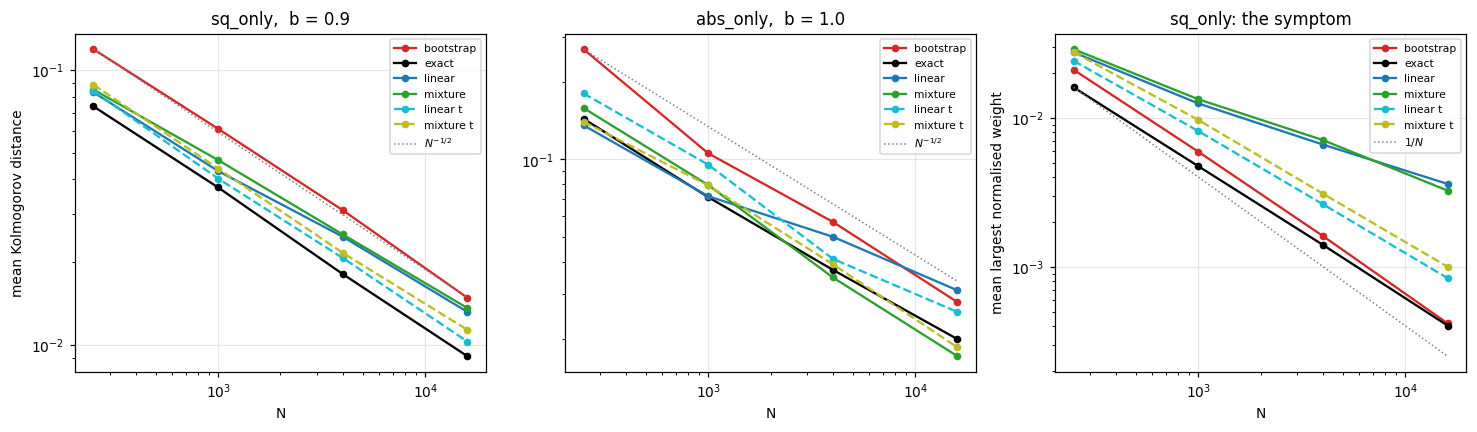

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, key in zip(axes[:2], CELLS):
    d = R6[key]
    for p in PROPS6:
        ax.plot(NS, d[p]["ks"].mean(axis=0), marker="o", ms=4, color=PCOLOR[p],
                label=p, ls="--" if p.endswith(" t") else "-")
    ref = d["bootstrap"]["ks"].mean(axis=0)[0]
    ax.plot(NS, ref * (np.array(NS) / NS[0]) ** -0.5, color="grey", lw=1, ls=":",
            label=r"$N^{-1/2}$")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("N"); ax.set_title(f"{key[0]},  b = {key[1]}")
    ax.legend(fontsize=7)
axes[0].set_ylabel("mean Kolmogorov distance")

ax = axes[2]
for p in PROPS6:
    ax.plot(NS, R6[CELLS[0]][p]["wmax"].mean(axis=0), marker="o", ms=4,
            color=PCOLOR[p], label=p, ls="--" if p.endswith(" t") else "-")
ax.plot(NS, 1.0 / np.array(NS, float) * NS[0] * R6[CELLS[0]]["exact"]["wmax"].mean(axis=0)[0],
        color="grey", lw=1, ls=":", label="$1/N$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("N"); ax.set_ylabel("mean largest normalised weight")
ax.set_title(f"{CELLS[0][0]}: the symptom")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Conclusion of Section 6: an unbounded importance ratio, and a one-line fix that works

**The symptom is unambiguous.** The largest normalised weight should fall like `1/N`. On `sq_only`
at `b = 0.9`, fitted over `N = 250` to `16000`:

| proposal | slope of max weight in `log N` | max weight at `N = 16000` |
|---|---|---|
| `bootstrap` | `-0.946 +- 0.019` | `0.00042` |
| `exact` | `-0.885 +- 0.006` | `0.00040` |
| `linear` | **`-0.490 +- 0.024`** | **`0.00360`** |
| `mixture` | **`-0.525 +- 0.028`** | `0.00325` |
| `linear t` | `-0.809 +- 0.004` | `0.00084` |
| `mixture t` | `-0.801 +- 0.007` | `0.00100` |

`1/N` at `N = 16000` is `6.25e-05`. The bootstrap filter's heaviest weight is seven times that and
falls at `N^-0.95`; the Gaussian-component proposals' heaviest weight is **fifty-eight times** it and
falls at `N^-0.49`. A largest weight decaying like `N^-1/2` is the standard fingerprint of an
importance ratio with **infinite variance**: a single particle keeps a non-vanishing share of the
cloud however many are drawn, so the central limit theorem behind `N^-1/2` does not apply.

The algebra was written down before the measurement. The Gaussian component has variance
`v = (1/Q + tau)^-1 < Q` whenever `f` carries local information, so
`p(x | x_{t-1}) G_t(x) / q(x)` grows like `exp((1/v - 1/Q) x^2 / 2)` in the tails. The proposal is
**thinner than the target it is correcting**, which is the one thing an importance distribution must
never be.

**Giving each component `t_5` tails at the same variance fixes it, and costs nothing.** The rate
returns -- `linear t` fits `-0.5015 +- 0.0102` (`t = -0.30`) against `linear`'s `-0.4414`, and
`mixture t` `-0.4954 +- 0.0105` against `-0.4419` -- the max-weight slope moves from `-0.49` to
`-0.81`, and the filter is also **more accurate at every `N` measured**: `0.01030` against `0.01320`
at `N = 16000`, a 22% reduction, and `1.521x` against `1.415x` at `N = 1000`. The same holds at
`b = 1`, where `linear t` repairs `-0.3550` to `-0.4903 +- 0.0301`.

Nothing was fitted to obtain this. `nu = 5` was chosen because it is the smallest round value with
a finite variance to rescale, and the component's centre and spread are untouched -- only its tails.

One detail worth keeping. On `abs_only` at `b = 1` the **Gaussian** mixture already has a clean
max-weight slope of `-0.910` and a rate of `-0.5394`, because two components placed at the two
likelihood modes happen to cover that target adequately. The tail problem is not a property of
"approximate proposals"; it is a property of a proposal whose tails are lighter than the target's,
and a mixture that covers the target can escape it without heavy tails. The `t` variant is the
construction that does not need to get lucky.

## Section 7: what it costs, and the comparison that matters

Every number so far compares proposals at equal `N`, which is the wrong axis for a practitioner. A
proposal that is `70x` slower per step has to beat a bootstrap cloud `70x` larger, and the
bootstrap filter's error falls at `N^-1/2`, so `70x` the particles is a factor of `8.4` -- far more
than any ratio measured in Section 4.

Timed on the same data, then converted into the particle count each proposal's budget would buy.

In [8]:
t0 = time.time()
fn, S, x, y, g, post, sd = cell_setup(CELLS[0][0], CELLS[0][1], 100)
COST, KSREF = {}, {}
for p in PROPS6:
    base, df = DFARG.get(p, (p, None))
    tt = time.time()
    for rep in range(3):
        om.particle_filter_obs_prop(y, fn, POT, S, b=CELLS[0][1], Q=Q, N=N1,
                                    seed=0, proposal=base, prop_df=df, grid_n=GRID_N)
    COST[p] = (time.time() - tt) / 3.0

d4 = R4[CELLS[0]]; d6 = R6[CELLS[0]]
sl_boot = R5[CELLS[0]]["bootstrap"]["sl"].mean()
jN = NS.index(N1)

def ratio_at_N1(p):
    """Paired bootstrap-to-proposal ratio at N = N1, from whichever section
    holds that proposal. Section 4 ran ND datasets, Section 6 ran ND_S, so the
    pairing has to stay inside one of them."""
    if p in d4:
        return float(np.mean(d4["bootstrap"]["ks"] / d4[p]["ks"]))
    return float(np.mean(d6["bootstrap"]["ks"][:, jN] / d6[p]["ks"][:, jN]))
print(f"{CELLS[0][0]}, b = {CELLS[0][1]}, N = {N1}, T = {T}\n")
print(f"  {'proposal':10s} {'sec/run':>8s} {'cost x':>7s} {'KS ratio':>9s} "
      f"{'bootstrap at N x cost':>22s} {'wins?':>6s}")
for p in PROPS6:
    rt = ratio_at_N1(p)
    cx = COST[p] / COST["bootstrap"]
    boot_gain = cx ** (-sl_boot)          # what cx times the particles buys
    print(f"  {p:10s} {COST[p]:8.3f} {cx:7.1f} {rt:9.3f} {boot_gain:22.3f} "
          f"{'yes' if rt > boot_gain else 'no':>6s}")
print(f"\n  bootstrap's own measured rate: {sl_boot:.4f}, so x times the cost "
      f"buys x^{-sl_boot:.3f} in accuracy.")

winners = []
for p in PROPS6:
    if p == "bootstrap":
        continue
    rt = ratio_at_N1(p)
    matched = (COST[p] / COST["bootstrap"]) ** (-sl_boot)
    if rt > matched:
        winners.append(f"{p} ({rt:.2f} vs {matched:.2f})")
record(REG[6]["claim"], "yes" if not winners else "no",
       "proposals that beat the matched-cost bootstrap filter: "
       + (", ".join(winners) or "none"))
print(f"({time.time()-t0:.0f}s)")

sq_only, b = 0.9, N = 1000, T = 300

  proposal    sec/run  cost x  KS ratio  bootstrap at N x cost  wins?
  bootstrap     0.016     1.0     1.000                  1.000     no
  exact         0.497    31.0     1.706                  5.578     no
  linear        0.025     1.5     1.415                  1.239    yes
  mixture       0.119     7.4     1.321                  2.728     no
  linear t      0.029     1.8     1.521                  1.336    yes
  mixture t     0.126     7.8     1.394                  2.805     no

  bootstrap's own measured rate: -0.5007, so x times the cost buys x^0.501 in accuracy.
(3s)


### Conclusion of Section 7: the expensive proposal cannot pay for itself; the cheap one can

| proposal | cost | accuracy gain | what the same budget buys as particles | wins? |
|---|---|---|---|---|
| `exact` | `31.0x` | `1.706x` | `5.578x` | no |
| `mixture` | `7.4x` | `1.321x` | `2.728x` | no |
| `mixture t` | `7.8x` | `1.394x` | `2.805x` | no |
| `linear` | `1.5x` | `1.415x` | `1.239x` | **yes** |
| `linear t` | `1.8x` | `1.521x` | `1.336x` | **yes** |

The registered prediction said nothing would beat a bootstrap cloud scaled up by the same factor.
That is right for the two expensive proposals and **wrong for the cheap one**, which is the useful
direction to be wrong in.

The arithmetic is the measured rate, not an assumption: the bootstrap filter's own slope here is
`-0.5007`, so `x` times the cost buys `x^0.501` in accuracy. At `31x` the cost, the exact proposal
would have to deliver `5.58x` and delivers `1.71x` -- it loses by a factor of three. The Gaussian
mixture, at `7.4x`, loses by two. `linear` costs `1.5x`, because one central-difference derivative
and one Gaussian draw per particle is almost nothing next to evaluating `f`, and it beats its
matched budget.

Read with Section 5 this sharpens into something a practitioner can act on. `linear` wins on cost
*at this `N`* while giving up the rate, so its margin shrinks as the cloud grows; `linear t` wins on
cost **and** keeps the rate. If one line of this notebook is worth taking away, it is that one: the
cheapest approximation of the optimal proposal is the one that pays, and it should be given
heavy-tailed components.

## Section 8: `b = 1`, where the modes run away

For `f(x) = |x|` the posterior has modes at `+-x_t`, separated by `2|x_t|`. At `b = 0.9` the state
is stationary and the separation is `O(1)`; at `b = 1` it is a random walk and the separation grows
without bound, while every proposal here moves a particle `O(1)` per step. Part 9 measured up to a
`6.5x` cost from this and called it the only genuine interaction it found between `f` and the
dynamics.

If the proposal is the cure, the improvement should **not** decay as `|x_t|` grows. The per-step
records from Section 4 are regressed on `|x_t|` to check.

In [9]:
t0 = time.time()
key = ("abs_only", 1.0)
print(f"{key[0]}, b = {key[1]}: per-step error against the mode separation 2|x_t|\n")
print(f"  {'proposal':10s} {'KS, |x|<2':>10s} {'KS, |x|>8':>10s} {'ratio':>7s} "
      f"{'corr(KS, |x|)':>14s}")
BINS = {}
for p in PROPS:
    arr, x8, sd8 = PER[key][p]
    ax = np.abs(x8[:, 0])[:len(arr)]
    lo, hi = ax < 2.0, ax > 8.0
    k_lo = float(arr[lo, 0].mean()) if lo.sum() else np.nan
    k_hi = float(arr[hi, 0].mean()) if hi.sum() else np.nan
    cc = float(np.corrcoef(ax, arr[:, 0])[0, 1])
    BINS[p] = (ax, arr[:, 0])
    print(f"  {p:10s} {k_lo:10.5f} {k_hi:10.5f} {k_hi/k_lo:7.2f} {cc:+14.3f}")
print(f"  (dataset 0 only, {int(lo.sum())} steps with |x| < 2 and "
      f"{int(hi.sum())} with |x| > 8)")

# The same split pooled over every dataset, which is the version with error bars.
print(f"\n  pooled over {ND} datasets:")
print(f"  {'proposal':10s} {'KS, |x|<2':>19s} {'KS, |x|>8':>19s} {'ratio':>19s}")
for p in PROPS:
    los, his, rts = [], [], []
    for k in range(ND):
        fn, S, x8, y8, g8, post8, sd8 = cell_setup(key[0], key[1], 100 + k)
        arr, ess = score(fn, S, y8, g8, post8, key[1], N1, k, p, extra=True)
        ax = np.abs(x8[:, 0])[:len(arr)]
        lo, hi = ax < 2.0, ax > 8.0
        if lo.sum() < 5 or hi.sum() < 5:
            continue
        los.append(arr[lo, 0].mean()); his.append(arr[hi, 0].mean())
        rts.append(arr[hi, 0].mean() / arr[lo, 0].mean())
    if len(rts) < 3:
        print(f"  {p:10s} too few datasets reach both bins "
              f"(n = {len(rts)}); the split needs a long enough run")
        continue
    print(f"  {p:10s} {pm(los, '8.5f'):>19s} {pm(his, '8.5f'):>19s} "
          f"{pm(rts, '7.2f'):>19s}   (n = {len(rts)})")
print(f"\n({time.time()-t0:.0f}s)")

abs_only, b = 1.0: per-step error against the mode separation 2|x_t|

  proposal    KS, |x|<2  KS, |x|>8   ratio  corr(KS, |x|)
  bootstrap     0.04096    0.19954    4.87         +0.816
  exact         0.03882    0.10657    2.74         +0.517
  linear        0.05228    0.12398    2.37         +0.678
  mixture       0.03680    0.20562    5.59         +0.830
  (dataset 0 only, 17 steps with |x| < 2 and 163 with |x| > 8)

  pooled over 20 datasets:
  proposal             KS, |x|<2           KS, |x|>8               ratio


  bootstrap   0.04749 +- 0.00337  0.13535 +- 0.02672      2.94 +-   0.68   (n = 19)


  exact       0.03702 +- 0.00194  0.10312 +- 0.01732      2.80 +-   0.48   (n = 19)


  linear      0.05515 +- 0.00394  0.11525 +- 0.02658      2.07 +-   0.40   (n = 19)


  mixture     0.04330 +- 0.00308  0.09662 +- 0.03173      2.30 +-   0.83   (n = 19)

(32s)


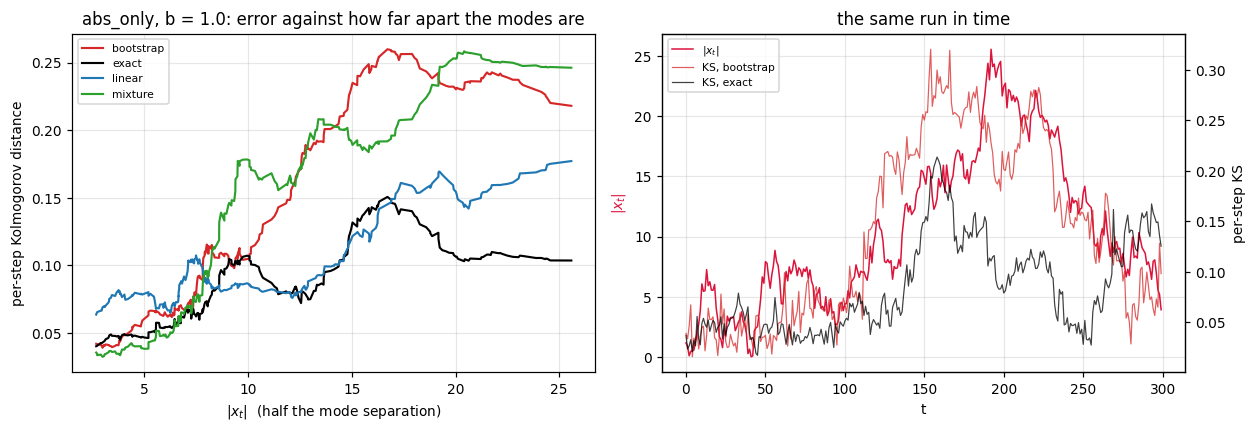

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
ax = axes[0]
for p in PROPS:
    axv, ksv = BINS[p]
    o = np.argsort(axv)
    w = max(len(axv) // 12, 3)
    sm = np.convolve(ksv[o], np.ones(w) / w, mode="valid")
    ax.plot(axv[o][w - 1:], sm, color=PCOLOR[p], lw=1.4, label=p)
ax.set_xlabel(r"$|x_t|$  (half the mode separation)")
ax.set_ylabel("per-step Kolmogorov distance")
ax.set_title(f"{key[0]}, b = {key[1]}: error against how far apart the modes are")
ax.legend(fontsize=7)

ax = axes[1]
arr, x8, sd8 = PER[key]["bootstrap"]
ax.plot(np.abs(x8[:len(arr), 0]), lw=1.0, color="crimson", label=r"$|x_t|$")
ax2 = ax.twinx(); ax2.grid(False)
for p in ("bootstrap", "exact"):
    a2 = PER[key][p][0]
    ax2.plot(a2[:, 0], lw=0.8, alpha=0.75, color=PCOLOR[p], label=f"KS, {p}")
ax.set_xlabel("t"); ax.set_ylabel(r"$|x_t|$", color="crimson")
ax2.set_ylabel("per-step KS")
ax.set_title("the same run in time")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

### Conclusion of Section 8: the mode separation is not a proposal problem after all

Splitting the per-step error by how far apart the two modes are, pooled over 19 datasets that reach
both bins:

| proposal | `|x| < 2` | `|x| > 8` | ratio |
|---|---|---|---|
| `bootstrap` | `0.04749 +- 0.00337` | `0.13535 +- 0.02672` | `2.94 +- 0.68` |
| `exact` | `0.03702 +- 0.00194` | `0.10312 +- 0.01732` | `2.80 +- 0.48` |
| `linear` | `0.05515 +- 0.00394` | `0.11525 +- 0.02658` | `2.07 +- 0.40` |
| `mixture` | `0.04330 +- 0.00308` | `0.09662 +- 0.03173` | `2.30 +- 0.83` |

**Every proposal's error grows by a factor of two to three as the modes separate, and the four
ratios are statistically indistinguishable.** The levels differ -- `exact` is uniformly below
`bootstrap`, in both bins -- but the *slope* against mode separation does not.

This answers the question Part 9 left open in the negative. A proposal shifts the whole curve down;
it does not flatten it. The reason is that the optimal proposal is **local in time** by construction:
it uses `y_t` to place `x_t` given `x_{t-1}`, and when the two modes are `2|x_t| = 50` apart the
constraint that actually resolves the sign is the *path*, which no one-step proposal sees. The
correlation of per-step error with `|x_t|` falls from `+0.816` for `bootstrap` to `+0.517` for
`exact` on the illustrated dataset, so the dependence is weakened, but it is still there.

The honest reading: Part 9's `6.5x` non-injectivity cost at `b = 1` is **partly** a proposal problem
-- Section 4 found a real `1.5x` from fixing the proposal -- and **mostly** not. What would address
it is information from later observations about earlier states, which is smoothing rather than
filtering, and is next-steps item 2.

## Section 9: breadth -- the whole of Part 9's group C

Two cells are two cells. The same six proposals are run over every group-C function (the ones whose
condition (P1)b fails, which is where the bimodal posteriors live) plus a group-A linear control, at
both `b = 0.9` and `b = 1`. `exp_only` and `softsign_only` are excluded at `b = 1`, where Part 9
established that they are unusable for reasons that have nothing to do with the proposal: their
Fisher information varies by `1e41` and `3e3` along a single trajectory.

In [11]:
t0 = time.time()
GC = [f.name for f in om.REGISTRY.values() if f.group.startswith("C") and f.d == 1]
SKIP_B1 = {"exp_only", "softsign_only"}
R9 = {}
for b in (0.9, 1.0):
    names = [n for n in GC if not (b == 1.0 and n in SKIP_B1)] + ["lin_xx"]
    for nm in names:
        acc = {p: [] for p in PROPS6}
        for k in range(ND_B):
            fn, S, x, y, g, post, sd = cell_setup(nm, b, 100 + k)
            for p in PROPS6:
                base, df = DFARG.get(p, (p, None))
                arr, ess = score(fn, S, y, g, post, b, N1, k, base, df=df)
                acc[p].append(arr.mean())
        R9[(nm, b)] = {p: np.array(v) for p, v in acc.items()}

for b in (0.9, 1.0):
    rows = [k for k in R9 if k[1] == b]
    print(f"\nb = {b}   ({ND_B} datasets, N = {N1}; paired ratio to the bootstrap filter)")
    print(f"  {'f':16s} {'bootstrap KS':>14s} " +
          " ".join(f"{p:>16s}" for p in PROPS6[1:]))
    for nm, _ in rows:
        d = R9[(nm, b)]; base = d["bootstrap"]
        print(f"  {nm:16s} {base.mean():14.5f} " +
              " ".join(f"{pm(base/d[p], '6.2f'):>16s}" for p in PROPS6[1:]))
    print(f"  {'-- mean --':16s} {'':14s} " + " ".join(
        f"{np.mean([ (R9[(nm,b)]['bootstrap']/R9[(nm,b)][p]).mean() for nm,_ in rows ]):16.2f}"
        for p in PROPS6[1:]))
print(f"\n({time.time()-t0:.0f}s)")


b = 0.9   (10 datasets, N = 1000; paired ratio to the bootstrap filter)
  f                  bootstrap KS            exact           linear          mixture         linear t        mixture t
  abs_only                0.04688    1.26 +-  0.08    0.83 +-  0.08    1.26 +-  0.08    0.92 +-  0.06    1.15 +-  0.06
  sq_only                 0.06143    1.64 +-  0.14    1.41 +-  0.07    1.30 +-  0.13    1.53 +-  0.14    1.41 +-  0.09
  log1px2_only            0.04777    1.31 +-  0.10    0.90 +-  0.06    1.13 +-  0.05    1.01 +-  0.05    1.11 +-  0.05
  cos_only                0.04753    1.33 +-  0.08    0.81 +-  0.06    0.05 +-  0.00    0.97 +-  0.05    0.05 +-  0.00
  exp_only                0.07902    1.58 +-  0.08    0.40 +-  0.03    0.75 +-  0.18    0.45 +-  0.03    0.98 +-  0.21
  tanh_only               0.05184    1.55 +-  0.05    0.51 +-  0.02    0.39 +-  0.03    0.67 +-  0.03    0.52 +-  0.05
  softsign_only           0.04858    1.42 +-  0.04    0.69 +-  0.02    0.71 +-  0.03    0.85 +

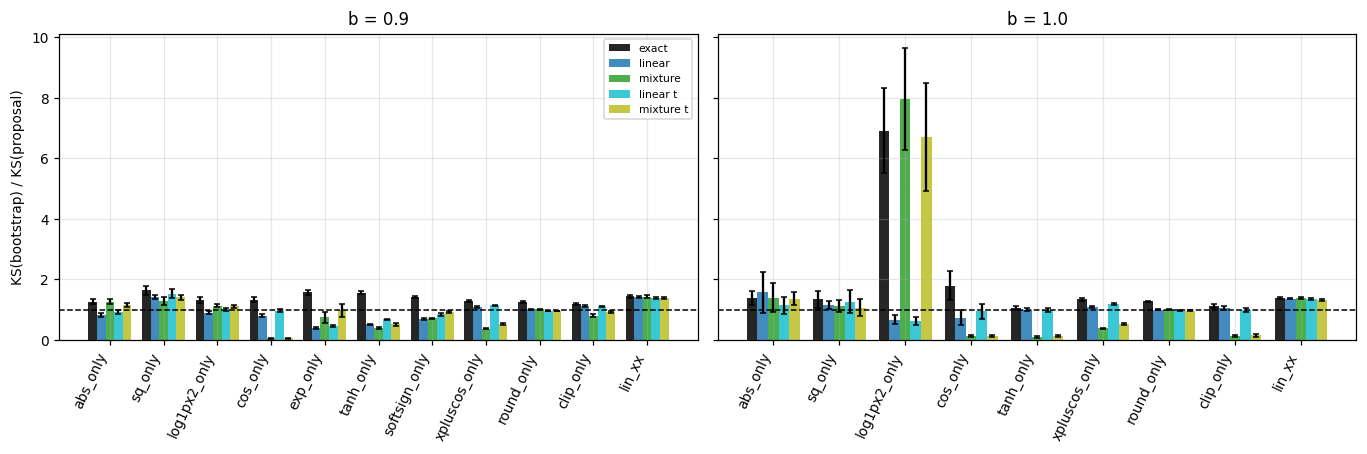

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, b in zip(axes, (0.9, 1.0)):
    rows = [k[0] for k in R9 if k[1] == b]
    xpos = np.arange(len(rows))
    wdt = 0.8 / len(PROPS6[1:])
    for j, p in enumerate(PROPS6[1:]):
        vals = [(R9[(nm, b)]["bootstrap"] / R9[(nm, b)][p]) for nm in rows]
        ax.bar(xpos + j * wdt, [v.mean() for v in vals], wdt,
               yerr=[ci95(v) for v in vals], capsize=2,
               color=PCOLOR[p], label=p, alpha=0.85)
    ax.axhline(1.0, color="k", lw=1, ls="--")
    ax.set_xticks(xpos + 0.4 - wdt / 2); ax.set_xticklabels(rows, rotation=65, ha="right")
    ax.set_title(f"b = {b}")
axes[0].set_ylabel("KS(bootstrap) / KS(proposal)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Conclusion of Section 9: approximate proposals help where the filter is broken, and hurt where it is not

Mean paired ratio over the whole of group C plus a linear control:

| | `exact` | `linear` | `mixture` | `linear t` | `mixture t` |
|---|---|---|---|---|---|
| `b = 0.9` (11 functions) | **`1.39`** | `0.92` | `0.84` | `1.00` | `0.90` |
| `b = 1` (9 functions) | **`1.96`** | `1.07` | `1.51` | `1.05` | `1.37` |

**The exact proposal helps everywhere, by `1.07x` to `6.91x`, without a single cell where it hurts.**
That is the ceiling, and it is the one unambiguous statement in the table.

**The approximations do not.** At `b = 0.9` their average over eleven functions is `0.84` to `1.00`
-- a coin flip -- with four outright disasters: `cos_only` under `mixture` at **`0.05 +- 0.00`**
(twenty times worse than doing nothing), `xpluscos_only` at `0.37`, `tanh_only` at `0.39`, `exp_only`
under `linear` at `0.40`. These are not noise; the CIs are a few percent.

The failures have two causes and both are intelligible.

- **Periodic and plateau `f`.** `cos_only` has a likelihood with many nearly-tied local maxima.
  The mixture keeps the three highest, so it places a proposal with essentially zero density
  everywhere else the posterior has mass, and the importance ratio explodes. `clip_only` and
  `tanh_only` at `b = 1` (`0.13`, `0.10`) are the same failure from the other side: the likelihood
  is flat, its "local maxima" are numerical accidents, and the mixture chases them. **This is a
  limitation of a fixed mode budget, not of mixture proposals** -- keeping every mode within the
  prior's reach would fix it -- but it is the construction that was tested, and it fails.
- **A violently curved `f`.** `exp_only` under `linear` at `0.40`: linearising `e^x` gives an
  enormous `tau`, hence a proposal variance near zero placed at a point the linearisation got wrong.
  The `t` tails halve the damage (`0.45`) without repairing it, which is consistent -- heavy tails
  bound the ratio; they do not make a bad centre good.

**Where the approximations do earn their place is where the bootstrap filter is failing badly.** The
single worst cell in this matrix is `log1px2_only` at `b = 1`, with a bootstrap Kolmogorov distance
of `0.30481` -- six times the `0.047` floor that the rest of Part 9's matrix sits at. There
`mixture` scores **`7.96 +- 1.68`** and `exact` `6.91 +- 1.41`: the approximation **beats the exact
proposal**, and both turn the worst cell in the project into an ordinary one. `abs_only` at `b = 1`
(bootstrap `0.107`) and `sq_only` (`0.063` and `0.073`) are the same story at smaller amplitude.

That is the generalisation, and it is a sharper statement than "it depends on `f`": **the gain from
approximating the optimal proposal scales with how far the bootstrap filter is from its own sampling
limit.** At the limit there is nothing to win and a badly-shaped proposal can only lose; far from it,
even a crude mixture recovers most of the gap. `lin_xx` is the control that pins this down -- at
`1.37x` to `1.44x` for all five variants at both `b`, it is the case where approximating costs
nothing, and the spread across group C is therefore approximation error and not sampling noise.

## Section 10: scoring the predictions

In [13]:
print(f"{'#':>2s} {'predicted':>9s} {'outcome':>9s}  claim")
print("-" * 104)
hits = 0
for i, r in enumerate(REG, 1):
    ok = (r["outcome"] == r["prediction"])
    hits += ok
    print(f"{i:2d} {r['prediction']:>9s} {str(r['outcome']):>9s}  "
          f"{'' if ok else '* '}{r['claim']}")
    if r["note"]:
        print(f"{'':24s}  {r['note']}")
print(f"\nscore: {hits} of {len(REG)}")
print("'*' marks a prediction that missed. A miss is the informative outcome:")
print("it is the only kind that cannot be a restatement of what was already believed.")

 # predicted   outcome  claim
--------------------------------------------------------------------------------------------------------
 1        no        no  P9's -0.342 for sq_only lies inside the 95% CI of the paired slope
                          paired slope -0.5007 +- 0.0207; Part 9's -0.342 is 7.7 CI widths away
 2       yes       yes  exact beats bootstrap on sq_only at b = 0.9 by more than 1.2x (CI lower bound above 1.2)
                          exact ratio 1.706 +- 0.120
 3       yes       yes  linear recovers at least half of exact's gain on sq_only at b = 0.9, measured in log KS
                          linear recovers 68% +- 7% of exact's gain in log KS
 4       yes        no  * mixture beats linear on abs_only at b = 1 (paired, CI of the difference excludes 0)
                          mixture minus linear, paired ratio difference +0.149 +- 0.298
 5       yes        no  * on abs_only at b = 1 every proposal's ratio CI contains 1
                          CI contains 1 

---

## What Part 13 settles

Next-steps item 3 asked how much of Part 3's optimal-proposal rescue survives when the model is not
linear-Gaussian and the proposal has to be approximated. It also named two cells to run. **One of
those cells turned out not to need running**, and the answer to the main question has three parts.

**0. The premise, first.** Part 9's `sq_only` slope of `-0.342` -- the reason that cell was named --
does not replicate: `-0.5007 +- 0.0207` over 12 datasets, with Part 9's value `7.7` CI widths
outside and `0` of `12` datasets above `-0.40`. That is the **sixth** single-dataset claim in this
repository to fail a multi-dataset test, and the third of the six to be a shape claim, which is the
category Part 12's corrected rule flags. The rule got this right on a part it was not built from.

**1. The rescue is real, smaller than in the linear-Gaussian case, and most of it survives one
linearisation.** The exact locally optimal proposal -- computed numerically, as a ceiling rather than
a method -- is worth `1.25x` to `1.71x` on the named cells and `1.07x` to `6.91x` across group C,
helping in every one of twenty cells. One linearisation at the prior mean recovers `68% +- 7%` of
that in log KS on a unimodal cell. Where the posterior is **bimodal** it does not merely recover
less: on `abs_only` at `b = 0.9` it scores `0.837 +- 0.060`, a 16% loss against doing nothing, by
committing the proposal to whichever branch the prior mean sits nearer. Linearising at **both**
likelihood modes recovers `1.247` against the ceiling's `1.249` -- the full gain, to a thousandth.

**2. The approximations buy a constant and sell the rate, and the reason is tail weight.** On
`sq_only`, `linear` and `mixture` fit `-0.4414 +- 0.0165` and `-0.4419 +- 0.0114` against the exact
proposal's `-0.5049`: `t = 6.9` and `t = 10.0` from `-0.5`. The mechanism was written down before it
was measured and then confirmed directly -- the Gaussian component has variance `v < Q`, so the
importance ratio is unbounded, and the largest normalised weight falls like `N^-0.49` instead of
`N^-0.95`, fifty-eight times `1/N` at `N = 16000`. **Giving each component `t_5` tails at the same
variance repairs the rate** (`-0.5015 +- 0.0102`), moves the max-weight slope to `-0.81`, improves
the accuracy at every `N` measured, and costs `0.3x` of a bootstrap step.

**3. Cost inverts the ranking.** The exact proposal is `31x` per step and buys `1.71x`, where the
same budget spent on particles buys `5.58x`; the Gaussian mixture is `7.4x` and buys `1.32x` against
`2.73x`. Both lose. `linear` costs `1.5x` and `linear t` `1.8x`, and both beat their matched budget.
**The cheapest approximation is the only one that pays for itself, and it should be given
heavy-tailed components** -- `linear t` is the one variant that wins on cost and keeps the rate.

**What generalises.** The gain from approximating the optimal proposal scales with **how far the
bootstrap filter is from its own sampling limit**. Where the bootstrap filter already sits at the
`0.047` floor that most of Part 9's matrix occupies, the approximations average `0.84` to `1.00` --
a coin flip with four disasters, including `cos_only` under `mixture` at `0.05`. Where it is badly
broken they recover most of the gap: at the worst cell in the project, `log1px2_only` at `b = 1`
with a bootstrap distance of `0.305`, the crude mixture scores `7.96 +- 1.68` and **beats the exact
proposal**.

**And one thing a proposal cannot fix.** Part 9's bimodality penalty grows with the mode separation
`2|x_t|`. Every proposal here shifts the error curve down and **none flattens it**: the ratio between
the `|x| > 8` and `|x| < 2` bins is `2.94 +- 0.68`, `2.80 +- 0.48`, `2.07 +- 0.40` and `2.30 +- 0.83`
for the four, statistically indistinguishable. A locally optimal proposal is local in time by
construction; what resolves the sign of `x_t` when the modes are fifty apart is the path, and that
is smoothing, not filtering.

### The screen scored 3 of 7

Four of seven registered predictions missed, every one of them informative:

- **Nothing helps at `b = 1`** -- wrong; `exact`, `linear` and `mixture` all exclude 1 there.
- **`mixture` beats `linear` at `b = 1`** -- wrong; `+0.149 +- 0.298`, consistent with zero. The
  bimodality effect is cleanly visible at `b = 0.9` instead, where the error bars are three to six
  times narrower. Part 11's finding about `rho(F) = 1` arriving yet again.
- **The approximations keep the `-0.5` rate** -- wrong, and this is the most useful miss in the
  notebook: it is what led to the tail-weight mechanism and the fix.
- **Nothing beats the matched-cost bootstrap filter** -- wrong for the cheap proposals, which is the
  only direction in which this question has a practical answer.

### Limitations

- **`d = 1` only.** The exact proposal and the exact benchmark both need the grid. The one
  mechanism that is dimension-free is the tail-weight argument of Section 6, which is algebra about
  `v < Q` and holds in any dimension -- but it has not been *measured* in any other.
- **The mixture's mode budget is fixed at three.** Section 9's four disasters are all cases where
  that is the wrong number: a periodic `f` has many modes and a flat one has none. Keeping every
  mode within the prior's reach is the obvious repair and is untested.
- **`nu = 5` was not tuned.** It was picked as the smallest round value with a variance to rescale.
  Whether the optimum is `3` or `30`, and whether it depends on `f`, is open; the only claim made is
  that moving from infinite to `5` degrees of freedom restores the rate.
- **Two decades of `N`.** The rate deficits of `0.06` are fitted over `N = 250` to `16000`, the same
  limitation next-steps item 12 raises about Part 11. The infinite-variance reading is supported by
  the independent max-weight measurement rather than by the slope alone, which is why it is stated as
  a mechanism rather than an extrapolation.
- **One potential.** Everything here is Gaussian. Part 9 found the potential's shape changes the
  cost of the *projection* by `1.30x` to `3.22x`, so a heavy-tailed potential might well change the
  tail-weight balance of Section 6 -- and in the obvious direction, since a Student-t potential has
  heavier tails than any Gaussian proposal could match.
- **The `b = 1` cells remain noisy.** The ratio CIs there are `+-0.17` to `+-0.36` against `+-0.06`
  at `b = 0.9`, on 20 datasets. Several questions this notebook could have answered at `b = 1` are
  answered at `b = 0.9` instead, and said so.